# Reinforcement Learning on a Shower: when is a neural network the right tool?

**The question:** a shower's temperature drifts, and you have a knob with three moves: a little colder, stay, a little hotter. Can an agent learn to hold the water in the sweet spot of **37 to 39 degrees** by trial and error? Yes, and this is a lovely first reinforcement-learning problem because it is small enough to **solve exactly**. That lets us ask better questions than "did it learn?". *Is learning even necessary, how much experience does it need, what makes it fail, and how far does what it learned carry?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. The shower (the environment)
4. Hypotheses and why we chose each test
5. The exact answer (no learning needed)
6. H1: does the agent need rescaled inputs?
7. H2: does a plain lookup table do as well as a neural network?
8. H3: does what it learned carry to temperatures it has not seen?
9. H4: does it survive a more restless shower?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab DL/rl-shower-temperature/rl_shower_temperature.ipynb`, or *Run All* in any Jupyter. Nothing is downloaded and it runs on a CPU in about 10 minutes.

## 1. 💡 The simple analogy

Imagine standing under a **shower that wanders on its own**: the pipes make the water a degree hotter or colder every second. You have one hand on the knob and you want to stay comfortable for a whole minute.

- The **agent** is you, the **action** is a nudge of the knob, and the **reward** is how you feel: +1 when the water is comfortable, -1 when it is not.
- **Reinforcement learning** is learning by doing: try things, notice what feels good, repeat what worked. At first the agent just twiddles the knob at random.
- A **policy** is the rule "at this temperature, nudge this way". A **thermostat rule** is the obvious one: if it is cold, nudge hotter; if hot, nudge colder.
- **Regret** is how much comfort the agent loses compared with the best possible rule. If the best rule scores 59 and the agent scores 40, its regret is 19.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the sweet-spot range and the learning budgets keeps the notebook reproducible and avoids "magic numbers". Everything is on a CPU: the problem is tiny.

In [1]:
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gymnasium import spaces
from matplotlib.ticker import NullFormatter
from scipy import stats
from stable_baselines3 import DQN

OUT_DIR = Path("outputs")
SEED = 365
N_SEEDS = 8  # independent trainings per setting
BUDGETS = [2_000, 10_000, 50_000]  # environment steps an agent may use for learning
N_BOOTSTRAP = 5_000
N_SIM_EPISODES = 2_000
LOW, HIGH = 0, 100  # the temperature dial's range
BAND = (37, 39)  # the sweet spot
EPISODE_LENGTH = 60  # seconds of shower
TRAIN_STARTS = np.arange(35, 42)  # 38 plus or minus 3: where the shower starts in training
GAMMA = 0.9
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
TEMPS = np.arange(LOW, HIGH + 1)

## 3. The shower (the environment)

*What:* the shower as a small program in the standard **Gymnasium** format that reinforcement-learning libraries understand. Each second, the agent picks an action: **0** (colder by 1 degree), **1** (keep) or **2** (hotter by 1 degree). The reward is **+1 if the temperature after the nudge is inside 37 to 39, otherwise -1**. Then the bathroom adds random drift of **-1, 0 or +1** degrees. A shower lasts **60 seconds** and starts at 38 plus or minus 3 degrees.

> **Problems in the legacy notebook this replaces:** it was written for Google Colab (a Drive mount and `!pip install tensorflow==2.3.0`), used the old `gym` API, a `random` module outside the environment's control (so runs could not be repeated), a temperature that could run outside the 0 to 100 limits it declared, `keras-rl2` and saved weights as `.h5f`. It trained a five-layer network for **500,000 steps**, fed it the **raw temperature** (around 38), and reported a single average score with no comparison to any simple rule or to the best possible answer.

In [2]:
class ShowerEnv(gym.Env):
    """A shower whose temperature drifts at random and can be nudged down, kept, or up.

    Each second the agent picks an action (0 = colder by 1, 1 = keep, 2 = hotter by 1). The reward
    is +1 if the temperature after that nudge is inside the sweet spot, otherwise -1. Then the
    bathroom adds random drift of up to ``noise`` degrees either way.

    Args:
        spread: The shower starts at 38 plus or minus up to ``spread`` degrees.
        noise: Largest random drift per second, in degrees.
        length: Seconds in a shower.
    """

    metadata = {"render_modes": []}

    def __init__(self, spread: int = 3, noise: int = 1, length: int = EPISODE_LENGTH) -> None:
        super().__init__()
        self.spread, self.noise, self.length = spread, noise, length
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(LOW, HIGH, shape=(1,), dtype=np.float32)
        self.temp, self.seconds = 38, 0

    def reset(self, *, seed: int | None = None, options: dict | None = None):
        """Starts a new shower (``options={"start_temp": t}`` forces the first temperature)."""
        super().reset(seed=seed)
        self.seconds = 0
        start = (options or {}).get("start_temp")
        if start is None:
            start = 38 + int(self.np_random.integers(-self.spread, self.spread + 1))
        self.temp = int(start)
        return np.array([self.temp], dtype=np.float32), {}

    def step(self, action: int):
        """Applies the nudge, scores it, adds the drift and moves the clock on by a second."""
        self.temp = int(np.clip(self.temp + int(action) - 1, LOW, HIGH))
        reward = 1.0 if BAND[0] <= self.temp <= BAND[1] else -1.0
        drift = int(self.np_random.integers(-self.noise, self.noise + 1))
        self.temp = int(np.clip(self.temp + drift, LOW, HIGH))
        self.seconds += 1
        truncated = self.seconds >= self.length  # a time limit, not a failure
        return np.array([self.temp], dtype=np.float32), reward, False, truncated, {}


class ScaledTemperature(gym.ObservationWrapper):
    """Shows the agent (temperature - 38) / 10 instead of the raw temperature."""

    def __init__(self, env: gym.Env) -> None:
        super().__init__(env)
        self.observation_space = spaces.Box(-5.0, 5.0, shape=(1,), dtype=np.float32)

    def observation(self, observation: np.ndarray) -> np.ndarray:
        """Rescales the temperature."""
        return (observation - 38.0) / 10.0


env = ShowerEnv()
obs, _ = env.reset(seed=SEED)
print(
    f"Start temperature {obs[0]:.0f}; actions: {env.action_space.n}; "
    f"observation space {env.observation_space}"
)
print("Sweet spot:", BAND, "| episode length:", EPISODE_LENGTH, "seconds")

Start temperature 35; actions: 3; observation space Box(0.0, 100.0, (1,), float32)
Sweet spot: (37, 39) | episode length: 60 seconds


**How to read this:**

- The environment works as designed: a first shower with a seed starts at a reproducible temperature (here **35**), there are **3 actions**, and temperature is an observation between 0 and 100.
- Unlike the legacy version, we **clip** the temperature to 0 to 100, **seed** the randomness, and end each shower with a *time limit* (`truncated`) rather than a failure.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does showing the agent a rescaled temperature help? | Same regret with raw and rescaled input | Rescaled is better | 8 paired seeds at each of three learning budgets, Wilcoxon, exact regret |
| H2 | Does a neural network beat a plain lookup table? | Same regret | Differs | 8 seeds at each budget, Mann-Whitney U |
| H3 | Does the learned rule work from starting temperatures it never saw? | Optimal everywhere | Fails outside the training range | Exact expected return from every starting temperature |
| H4 | Does the learned rule survive a more restless shower? | Same regret at higher drift | Regret rises | Exact expected return at drift 1, 2 and 3 degrees |

*Why exact scoring?* This shower has only 101 possible temperatures, so we can compute, with no sampling noise, the **exact expected score** of any rule, and the exact best possible score, by dynamic programming. Every "regret" below is therefore exact, and the only randomness is in the **learning**, which we capture with repeated seeds. *Why Wilcoxon and Mann-Whitney?* Regret is wildly skewed (many zeros, a few huge values), so rank-based tests are the safe choice. With 8 seeds the smallest possible Wilcoxon p-value is 0.008.

## 5. The exact answer (no learning needed)

*What:* we write the shower's rules as tables and score four fixed rules *exactly*: **twiddling the knob at random**, **never touching it**, a **thermostat rule** (nudge towards 38), and the **best possible rule**, found by dynamic programming (working backwards from the end of the shower). Then we check the exact numbers against **2,000 simulated showers** per rule.

*Why do this first?* It tells us what a learning agent has to beat, and what perfect looks like. This is the step the legacy notebook skipped.

In [3]:
def transition_model(noise: int = 1) -> tuple[np.ndarray, np.ndarray]:
    """The shower's rules written as tables, so every policy can be scored exactly.

    Args:
        noise: Largest random drift per second.

    Returns:
        ``P[a, s, s2]``: chance of moving from temperature s to s2 after action a, and
        ``R[a, s]``: the reward for choosing action a at temperature s.
    """
    P = np.zeros((3, len(TEMPS), len(TEMPS)))
    R = np.zeros((3, len(TEMPS)))
    for a in range(3):
        for s in TEMPS:
            moved = int(np.clip(s + a - 1, LOW, HIGH))
            R[a, s] = 1.0 if BAND[0] <= moved <= BAND[1] else -1.0
            for drift in range(-noise, noise + 1):
                P[a, s, int(np.clip(moved + drift, LOW, HIGH))] += 1 / (2 * noise + 1)
    return P, R


def policy_value(policy: np.ndarray, noise: int = 1) -> np.ndarray:
    """Exact expected total reward of a 60-second shower from every starting temperature.

    Args:
        policy: Action probabilities, shape (n_temperatures, 3).
        noise: Largest random drift per second.

    Returns:
        The expected return for each starting temperature.
    """
    P, R = transition_model(noise)
    value = np.zeros(len(TEMPS))
    for _ in range(EPISODE_LENGTH):
        value = np.einsum("sa,as->s", policy, R + np.einsum("ast,t->as", P, value))
    return value


def optimal_value(noise: int = 1) -> np.ndarray:
    """Expected total reward of the best possible policy (found by dynamic programming).

    Args:
        noise: Largest random drift per second.

    Returns:
        The best achievable expected return for each starting temperature.
    """
    P, R = transition_model(noise)
    value = np.zeros(len(TEMPS))
    for _ in range(EPISODE_LENGTH):
        value = (R + np.einsum("ast,t->as", P, value)).max(axis=0)
    return value


def deterministic(actions: np.ndarray) -> np.ndarray:
    """Turns one chosen action per temperature into a policy table."""
    table = np.zeros((len(TEMPS), 3))
    table[TEMPS, actions] = 1.0
    return table


def start_return(value: np.ndarray) -> float:
    """Average of a value curve over the temperatures the shower starts from in training."""
    return float(value[TRAIN_STARTS].mean())


uniform = np.full((len(TEMPS), 3), 1 / 3)
hold = deterministic(np.ones(len(TEMPS), dtype=int))
thermostat = deterministic(np.where(TEMPS < 38, 2, np.where(TEMPS > 38, 0, 1)))
best = optimal_value()
simple = {
    "Random knob": policy_value(uniform),
    "Never touch the knob": policy_value(hold),
    "Thermostat rule (push towards 38)": policy_value(thermostat),
    "Best possible (dynamic programming)": best,
}
for name, value in simple.items():
    print(
        f"{name:40s} expected return {start_return(value):7.2f}  "
        f"(from 38 degrees: {value[38]:6.2f})"
    )
gap_all = np.abs(best - simple["Thermostat rule (push towards 38)"])[5:96]
print(
    f"\nThermostat rule vs best possible, every start from 5 to 95 degrees: "
    f"largest gap {gap_all.max():.3f}"
)
print(
    f"Upper limit: a perfect run scores {EPISODE_LENGTH}; the best average from the "
    f"training starts is {start_return(best):.2f} because starts at 35 and 41 cost a step"
)

Random knob                              expected return  -35.27  (from 38 degrees: -31.10)
Never touch the knob                     expected return  -28.32  (from 38 degrees: -20.25)
Thermostat rule (push towards 38)        expected return   59.14  (from 38 degrees:  60.00)
Best possible (dynamic programming)      expected return   59.14  (from 38 degrees:  60.00)

Thermostat rule vs best possible, every start from 5 to 95 degrees: largest gap 0.000
Upper limit: a perfect run scores 60; the best average from the training starts is 59.14 because starts at 35 and 41 cost a step


In [4]:
def simulate(policy: np.ndarray, n_episodes: int, seed: int) -> np.ndarray:
    """Plays real showers with a policy and returns each episode's total reward.

    Args:
        policy: Action probabilities, shape (n_temperatures, 3).
        n_episodes: Number of showers.
        seed: Seed for the first shower; later ones use consecutive seeds.

    Returns:
        Total reward per episode.
    """
    sim_env = ShowerEnv()
    action_rng = np.random.default_rng(seed)
    totals = np.empty(n_episodes)
    for episode in range(n_episodes):
        obs, _ = sim_env.reset(seed=seed + episode)
        total, done = 0.0, False
        while not done:
            action = action_rng.choice(3, p=policy[int(obs[0])])
            obs, reward, _, done, _ = sim_env.step(action)
            total += reward
        totals[episode] = total
    return totals


rows = []
for name, table in [
    ("Random knob", uniform),
    ("Never touch the knob", hold),
    ("Thermostat rule (push towards 38)", thermostat),
]:
    totals = simulate(table, N_SIM_EPISODES, SEED)
    draws = [rng.choice(totals, len(totals)).mean() for _ in range(N_BOOTSTRAP)]
    low, high = np.percentile(draws, [2.5, 97.5])
    exact = start_return(simple[name])
    rows.append(
        {
            "policy": name,
            "simulated mean": totals.mean(),
            "ci_low": low,
            "ci_high": high,
            "exact value": exact,
            "exact inside the CI": bool(low <= exact <= high),
        }
    )
check = pd.DataFrame(rows).set_index("policy")
print(f"{N_SIM_EPISODES:,} simulated showers per policy against the exact answer:")
print(check.round(2).to_string())

2,000 simulated showers per policy against the exact answer:
                                   simulated mean  ci_low  ci_high  exact value  exact inside the CI
policy                                                                                              
Random knob                                -35.86  -36.71   -35.01       -35.27                 True
Never touch the knob                       -28.52  -29.56   -27.45       -28.32                 True
Thermostat rule (push towards 38)           59.24   59.17    59.30        59.14                False


**How to read this:**

- **Random knob: -35.27. Never touching it: -28.32.** Both are *worse than nothing useful*: the water wanders out of the sweet spot and stays out. From 38 degrees the numbers are -31.10 and -20.25.
- **The thermostat rule scores 59.14, exactly the best possible** (59.14). Across every starting temperature from 5 to 95 degrees the largest gap between the thermostat rule and the best possible rule is **0.000**. The perfect score is 60; the training starts average 59.14 because starting at 35 or 41 degrees costs one second outside the band.
- **So this problem does not *need* learning:** a one-line rule is already optimal. That is what makes it a perfect first RL problem: we know the right answer, so we can see exactly how well a learner does.
- **The simulation agrees with the exact answers** for the random rule (simulated -35.86, 95% CI -36.71 to -35.01, exact -35.27) and for never touching the knob (-28.52, CI -29.56 to -27.45, exact -28.32). For the thermostat the simulated mean is 59.24 (CI 59.17 to 59.30) and the exact value 59.14: the interval misses by 0.03 points, which a 95% interval does about once in 20 times (the sampled starting temperatures are not perfectly even).

## 6. H1: does the agent need rescaled inputs?

*What:* we train a **DQN** agent (a neural network that learns the value of each action, from the Stable-Baselines3 library: two hidden layers of 64) with **2,000, 10,000 and 50,000** steps of experience, 8 seeds each, in two ways: one agent sees the **raw temperature** (about 38), the other sees a **rescaled** one, (temperature - 38) / 10. Then we read out the agent's chosen action at every temperature, and score that rule *exactly*. The result is **regret**: the best possible score minus the agent's.

*Why it might matter:* a neural network likes inputs near zero with a spread of about one. A raw temperature of 38 puts every unit in a very flat, saturated part of the network, so learning is slow and fragile. This is the same lesson as standardising inputs in the housing project, and the legacy notebook fed the raw value.

In [5]:
def greedy_actions(model: DQN, scaled: bool) -> np.ndarray:
    """The action a trained DQN agent would pick at every temperature on the dial.

    Args:
        model: A trained agent.
        scaled: Whether it was trained on scaled temperatures.

    Returns:
        One action per temperature.
    """
    observations = TEMPS[:, None].astype(np.float32)
    if scaled:
        observations = (observations - 38.0) / 10.0
    actions, _ = model.predict(observations, deterministic=True)
    return np.asarray(actions, dtype=int)


def train_dqn(scaled: bool, steps: int, seed: int) -> np.ndarray:
    """Trains a DQN agent on the shower and returns its greedy policy table.

    Args:
        scaled: Whether to show the agent scaled temperatures.
        steps: Environment steps of experience the agent may use.
        seed: Seed for the agent and the shower.

    Returns:
        The policy table, shape (n_temperatures, 3).
    """
    train_env = ShowerEnv()
    train_env = ScaledTemperature(train_env) if scaled else train_env
    model = DQN(
        "MlpPolicy",
        train_env,
        learning_rate=1e-3,
        buffer_size=50_000,
        learning_starts=500,
        batch_size=64,
        gamma=GAMMA,
        train_freq=4,
        target_update_interval=250,
        exploration_fraction=0.3,
        exploration_final_eps=0.05,
        policy_kwargs={"net_arch": [64, 64]},
        seed=seed,
        device="cpu",
        verbose=0,
    )
    model.learn(steps)
    return deterministic(greedy_actions(model, scaled))


dqn_policies = {}
dqn_rows = []
for scaled in (False, True):
    for steps in BUDGETS:
        for seed in range(N_SEEDS):
            table = train_dqn(scaled, steps, seed)
            dqn_policies[(scaled, steps, seed)] = table
            value = policy_value(table)
            dqn_rows.append(
                {
                    "input": "scaled" if scaled else "raw",
                    "steps": steps,
                    "seed": seed,
                    "return": start_return(value),
                    "regret": start_return(best) - start_return(value),
                }
            )
dqn_results = pd.DataFrame(dqn_rows)
summary = dqn_results.groupby(["steps", "input"]).agg(
    mean_return=("return", "mean"),
    mean_regret=("regret", "mean"),
    worst_regret=("regret", "max"),
    seeds_optimal=("regret", lambda r: int((r < 1e-6).sum())),
)
print(
    f"Exact expected return of each trained agent ({N_SEEDS} seeds per row; best possible "
    f"{start_return(best):.2f}):"
)
print(summary.round(2).to_string())
for steps in BUDGETS:
    raw = dqn_results[(dqn_results["input"] == "raw") & (dqn_results["steps"] == steps)]
    scl = dqn_results[(dqn_results["input"] == "scaled") & (dqn_results["steps"] == steps)]
    diff = (
        raw.sort_values("seed")["regret"].to_numpy() - scl.sort_values("seed")["regret"].to_numpy()
    )
    wil = stats.wilcoxon(diff) if np.any(diff != 0) else None
    p_text = f"{wil.pvalue:.3f}" if wil is not None else "n/a"
    print(
        f"  {steps:>6,} steps: raw regret minus scaled regret {diff.mean():+.2f} "
        f"(scaled better in {(diff > 0).sum()} of {N_SEEDS}); Wilcoxon p = {p_text}"
    )

Exact expected return of each trained agent (8 seeds per row; best possible 59.14):
              mean_return  mean_regret  worst_regret  seeds_optimal
steps input                                                        
2000  raw          -46.98       106.12        116.30              0
      scaled        26.47        32.67         58.93              3
10000 raw          -30.25        89.39        116.30              0
      scaled        59.14         0.00          0.00              8
50000 raw            4.83        54.31         86.13              2
      scaled        59.14         0.00          0.00              8
   2,000 steps: raw regret minus scaled regret +73.45 (scaled better in 8 of 8); Wilcoxon p = 0.008
  10,000 steps: raw regret minus scaled regret +89.39 (scaled better in 8 of 8); Wilcoxon p = 0.008
  50,000 steps: raw regret minus scaled regret +54.31 (scaled better in 6 of 8); Wilcoxon p = 0.031


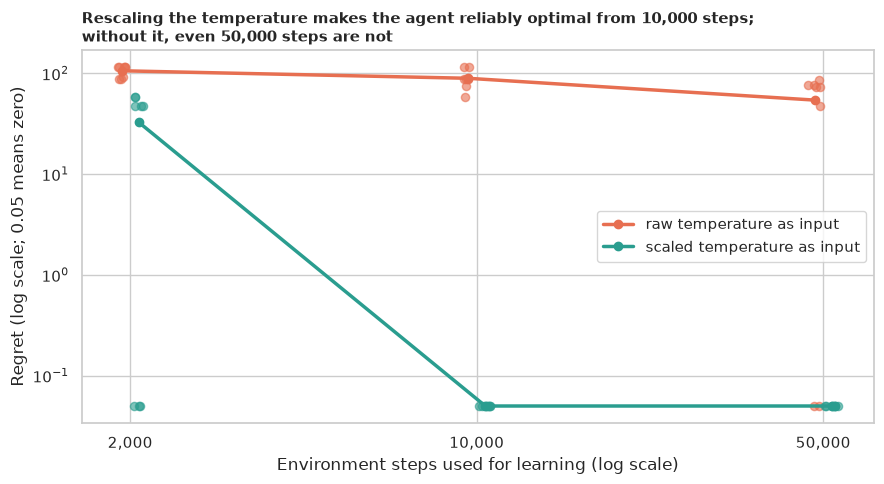

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for offset, (label, color) in zip([-0.04, 0.04], [("raw", ORANGE), ("scaled", TEAL)], strict=True):
    sub = dqn_results[dqn_results["input"] == label]
    for steps, grp in sub.groupby("steps"):
        jitter = rng.uniform(-0.03, 0.03, len(grp))
        ax.scatter(
            steps * np.exp(offset + jitter),
            grp["regret"].clip(lower=0.05),
            color=color,
            alpha=0.6,
            s=35,
        )
    means = sub.groupby("steps")["regret"].mean()
    ax.plot(
        means.index * np.exp(offset),
        means.clip(lower=0.05),
        color=color,
        lw=2.5,
        marker="o",
        label=f"{label} temperature as input",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(BUDGETS, [f"{b:,}" for b in BUDGETS])
ax.set_xlabel("Environment steps used for learning (log scale)")
ax.set_ylabel("Regret (log scale; 0.05 means zero)")
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_title(
    "Rescaling the temperature makes the agent reliably optimal from 10,000 steps;\n"
    "without it, even 50,000 steps are not",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "02_scaling.png", dpi=150)
plt.show()

**How to read this:**

- **Rescaling transforms the result.** With **10,000 steps** the rescaled agent is **exactly optimal in 8 of 8 seeds** (regret 0.00), while the raw-input agent is optimal in **0 of 8** (mean return -30.25, regret 89.39). With **50,000 steps** rescaled is still 8 of 8 optimal, while raw has reached the optimum in only **2 of 8** seeds (mean regret 54.31, worst 86.13).
- **At 2,000 steps** rescaled agents are optimal in **3 of 8** seeds (mean regret 32.67); raw agents in **0 of 8** (mean regret 106.12, which is about the worst possible: they act *against* the goal).
- **The tests agree:** scaled had lower regret in **8 of 8** pairs at 2,000 and 10,000 steps (Wilcoxon p = 0.008, the smallest value possible) and in **6 of 8** at 50,000 steps (p = 0.031). **We reject H₀.**
- **More experience does not fix a bad input:** the raw agent's regret falls from 106 to 89 to 54 as the budget grows 25 times, while the rescaled one hits 0 at 10,000 steps. This is what an unreliable input looks like in practice. The legacy notebook's 500,000 steps may well have been compensating for it.

## 7. H2: does a plain lookup table do as well as a neural network?

*What:* the oldest reinforcement-learning method, **Q-learning with a table**: one number for each (temperature, action) pair, updated after every second of experience, with the same exploration schedule, discount and budgets (2,000, 10,000 and 50,000 steps, 8 seeds). We compare its exact regret with the rescaled DQN. *Why:* a neural network is only worth its cost if it does something the table cannot. For a problem with 101 states, a table is the natural first thing to try.

In [7]:
def train_tabular(steps: int, seed: int) -> np.ndarray:
    """Q-learning with a lookup table: one number per (temperature, action).

    Args:
        steps: Environment steps of experience the learner may use.
        seed: Seed for exploration and the shower.

    Returns:
        The greedy policy table, shape (n_temperatures, 3).
    """
    table_env = ShowerEnv()
    explore = np.random.default_rng(seed)
    q = np.zeros((len(TEMPS), 3))
    obs, _ = table_env.reset(seed=seed)
    state = int(obs[0])
    for step in range(steps):
        epsilon = max(0.05, 1.0 - step / (0.3 * steps) * 0.95)
        action = int(explore.integers(3)) if explore.random() < epsilon else int(q[state].argmax())
        obs, reward, _, truncated, _ = table_env.step(action)
        nxt = int(obs[0])
        q[state, action] += 0.1 * (reward + GAMMA * q[nxt].max() - q[state, action])
        state = nxt
        if truncated:
            obs, _ = table_env.reset()
            state = int(obs[0])
    return deterministic(q.argmax(axis=1))


tab_policies = {}
tab_rows = []
for steps in BUDGETS:
    for seed in range(N_SEEDS):
        table = train_tabular(steps, seed)
        tab_policies[(steps, seed)] = table
        value = policy_value(table)
        tab_rows.append(
            {
                "steps": steps,
                "seed": seed,
                "return": start_return(value),
                "regret": start_return(best) - start_return(value),
            }
        )
tab_results = pd.DataFrame(tab_rows)
compare = pd.concat(
    [
        tab_results.assign(learner="lookup table"),
        dqn_results[dqn_results["input"] == "scaled"].assign(learner="DQN (scaled input)"),
    ]
)
learner_summary = compare.groupby(["steps", "learner"]).agg(
    mean_regret=("regret", "mean"),
    worst_regret=("regret", "max"),
    seeds_optimal=("regret", lambda r: int((r < 1e-6).sum())),
)
print(learner_summary.round(2).to_string())
for steps in BUDGETS:
    a = tab_results[tab_results["steps"] == steps]["regret"].to_numpy()
    b = dqn_results[(dqn_results["input"] == "scaled") & (dqn_results["steps"] == steps)][
        "regret"
    ].to_numpy()
    if np.ptp(np.concatenate([a, b])) > 0:
        mw = stats.mannwhitneyu(a, b)
        print(
            f"  {steps:>6,} steps: lookup table regret {a.mean():.2f} vs DQN {b.mean():.2f}; "
            f"Mann-Whitney p = {mw.pvalue:.3f}"
        )
    else:
        print(f"  {steps:>6,} steps: both learners are optimal in every seed")

                          mean_regret  worst_regret  seeds_optimal
steps learner                                                     
2000  DQN (scaled input)        32.67         58.93              3
      lookup table               0.05          0.43              7
10000 DQN (scaled input)         0.00          0.00              8
      lookup table               0.00          0.00              8
50000 DQN (scaled input)         0.00          0.00              8
      lookup table               0.00          0.00              8
   2,000 steps: lookup table regret 0.05 vs DQN 32.67; Mann-Whitney p = 0.029
  10,000 steps: both learners are optimal in every seed
  50,000 steps: both learners are optimal in every seed


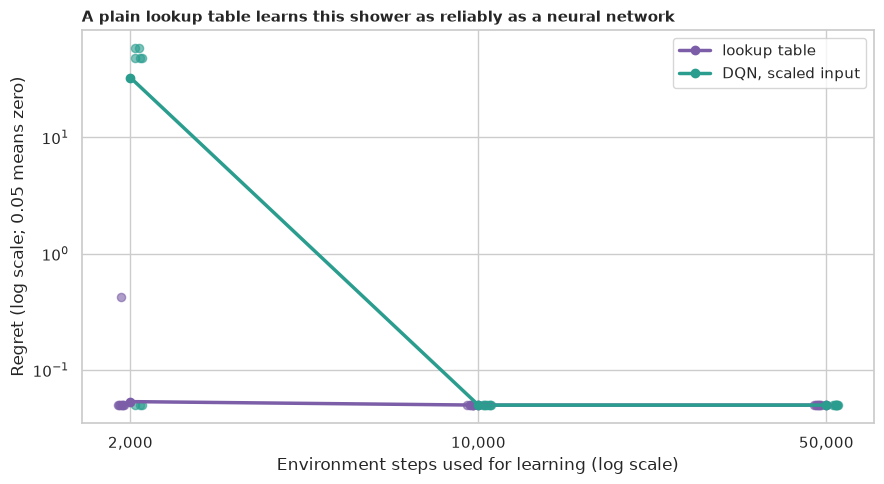

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, color, frame in [
    ("lookup table", PURPLE, tab_results),
    ("DQN, scaled input", TEAL, dqn_results[dqn_results["input"] == "scaled"]),
]:
    for steps, grp in frame.groupby("steps"):
        ax.scatter(
            np.full(len(grp), steps)
            * (0.96 if "table" in label else 1.04)
            * np.exp(rng.uniform(-0.02, 0.02, len(grp))),
            grp["regret"].clip(lower=0.05),
            color=color,
            alpha=0.6,
            s=35,
        )
    means = frame.groupby("steps")["regret"].mean()
    ax.plot(means.index, means.clip(lower=0.05), color=color, lw=2.5, marker="o", label=label)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(BUDGETS, [f"{b:,}" for b in BUDGETS])
ax.set_xlabel("Environment steps used for learning (log scale)")
ax.set_ylabel("Regret (log scale; 0.05 means zero)")
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_title(
    "A plain lookup table learns this shower as reliably as a neural network",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "03_learners.png", dpi=150)
plt.show()

**How to read this:**

- **The table learns faster than the neural network.** At **2,000 steps** the lookup table has a mean regret of **0.05** (optimal in 7 of 8 seeds, worst regret 0.43), against **32.67** for the rescaled DQN (optimal in 3 of 8). Mann-Whitney p = **0.029**. **We reject H₀**: here the simpler learner wins.
- **From 10,000 steps on, both are optimal in every seed** (regret 0.00).
- So for a one-dimensional problem with a handful of states, the neural network buys nothing, and costs far more computing time to train. Neural networks matter when the state is too big to tabulate (images, many continuous variables), and H3 shows what you give up in return.

## 8. H3: does what it learned carry to temperatures it has not seen?

*What:* during training, showers start between 35 and 41 degrees, so the agents only ever see a small slice of the dial. We take every trained agent (50,000 steps) and score its rule **exactly from every possible starting temperature** between 0 and 100: a shower that starts at 28 or 47 degrees is far outside anything it practised. We report the share of starting temperatures (10 to 90) from which the agent still gets within 1 point of the best possible score. *Why:* a rule that is right where it practised and wrong elsewhere is not really a rule; it is a memory.

In [9]:
BIG = BUDGETS[-1]
chosen = {
    "Thermostat rule": thermostat,
    "DQN, raw input, seed 0": dqn_policies[(False, BIG, 0)],
    "DQN, scaled input, seed 0": dqn_policies[(True, BIG, 0)],
    "Lookup table, seed 0": tab_policies[(BIG, 0)],
}
curves = {name: policy_value(table) for name, table in chosen.items()}
band_ok = {}
for name in ["DQN, raw input", "DQN, scaled input", "Lookup table"]:
    shares = []
    for seed in range(N_SEEDS):
        table = (
            dqn_policies[(False, BIG, seed)]
            if name == "DQN, raw input"
            else dqn_policies[(True, BIG, seed)]
            if name == "DQN, scaled input"
            else tab_policies[(BIG, seed)]
        )
        near = policy_value(table)[10:91] >= best[10:91] - 1.0
        shares.append(near.mean())
    band_ok[name] = np.array(shares)
    print(
        f"{name:20s}: within 1 point of optimal from {np.mean(shares):.0%} of the starting "
        f"temperatures 10 to 90 (seeds range {min(shares):.0%} to {max(shares):.0%})"
    )
inside = {
    name: float((curves[name][TRAIN_STARTS] >= best[TRAIN_STARTS] - 1).mean()) for name in curves
}
print("\nShare of the seven training starts (35 to 41) handled within 1 point of optimal:")
for name, share in inside.items():
    print(f"  {name:28s} {share:.0%}")

DQN, raw input      : within 1 point of optimal from 22% of the starting temperatures 10 to 90 (seeds range 0% to 90%)
DQN, scaled input   : within 1 point of optimal from 60% of the starting temperatures 10 to 90 (seeds range 37% to 100%)
Lookup table        : within 1 point of optimal from 21% of the starting temperatures 10 to 90 (seeds range 19% to 23%)

Share of the seven training starts (35 to 41) handled within 1 point of optimal:
  Thermostat rule              100%
  DQN, raw input, seed 0       100%
  DQN, scaled input, seed 0    100%
  Lookup table, seed 0         100%


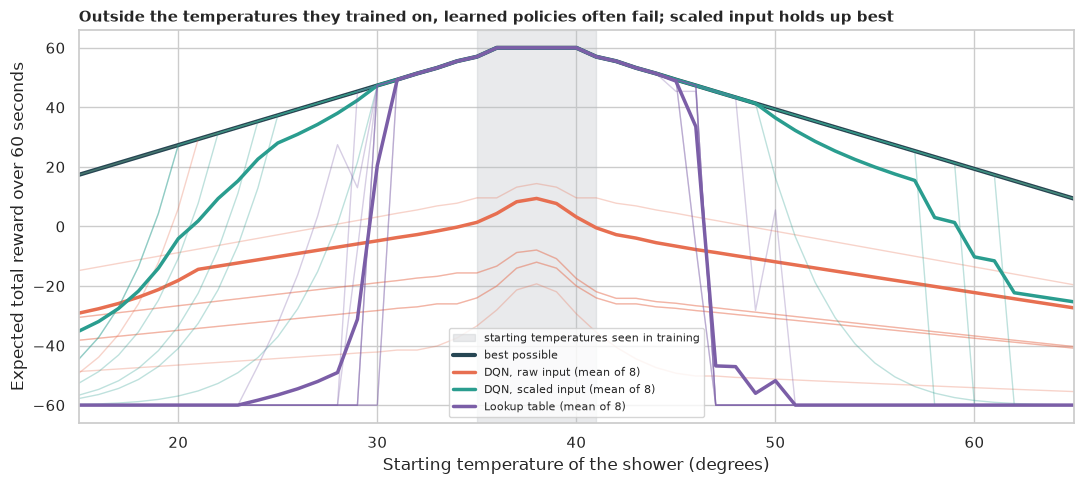

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(
    TRAIN_STARTS.min(),
    TRAIN_STARTS.max(),
    color=GREY,
    alpha=0.3,
    label="starting temperatures seen in training",
)
ax.plot(TEMPS, best, color=NAVY, lw=3, label="best possible")
seed_curves = {
    "DQN, raw input": [policy_value(dqn_policies[(False, BIG, s)]) for s in range(N_SEEDS)],
    "DQN, scaled input": [policy_value(dqn_policies[(True, BIG, s)]) for s in range(N_SEEDS)],
    "Lookup table": [policy_value(tab_policies[(BIG, s)]) for s in range(N_SEEDS)],
}
for (name, group), color in zip(seed_curves.items(), [ORANGE, TEAL, PURPLE], strict=True):
    for curve in group:
        ax.plot(TEMPS, curve, color=color, lw=1, alpha=0.3)
    ax.plot(TEMPS, np.mean(group, axis=0), color=color, lw=2.5, label=f"{name} (mean of {N_SEEDS})")
ax.set_xlim(15, 65)
ax.set_xlabel("Starting temperature of the shower (degrees)")
ax.set_ylabel("Expected total reward over 60 seconds")
ax.set_title(
    "Outside the temperatures they trained on, learned policies often fail; "
    "scaled input holds up best",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8, loc="lower center")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_generalisation.png", dpi=150)
plt.show()

**How to read this:**

- **Inside the training range the seed-0 agents are all perfect** (35 to 41 degrees: 100% of starts for each), but seed 0 is the lucky seed for the raw-input agent: over all eight seeds the raw-input agents average a return of only **4.83** over those starting temperatures (best possible 59.14), as H1 showed.
- **Outside it, most fail.** Averaged over seeds, the agents are within 1 point of optimal from **22%** of the starting temperatures (10 to 90) for the raw-input DQN (seeds range from **0% to 90%**), **60%** for the rescaled DQN (**37% to 100%**) and **21%** for the lookup table (**19% to 23%**). **We reject H₀.**
- **The lookup table's failure is built in:** a table entry that was never visited keeps its starting value, so the agent just picks the first action (colder) in all those temperatures. Depending on the seed, its policy collapses to the worst possible score (-60) somewhere between about 24 and 30 degrees on the low side and 46 and 51 degrees on the high side.
- **The neural network extrapolates, sometimes:** a smooth network carries the "go towards 38" pattern past the edge of its experience, so the rescaled DQN's average curve stays close to the best possible over roughly 25 to 50 degrees before falling away. But each faint teal line is one seed, and they fall off at very different places: the spread of 37% to 100% across seeds is the warning that extrapolation is luck, not design.
- **The thermostat rule has no such problem:** it is optimal at every starting temperature, because it is a *rule*, not a record of what was seen.

## 9. H4: does it survive a more restless shower?

*What:* we keep the rules the agents learned in the normal shower (drift of 1 degree) and test them, exactly, in showers where the temperature drifts up to **2** or **3** degrees each second. Each is compared with the best possible rule *for that drift* (found by dynamic programming again). The agents are the 8 rescaled DQN and 8 lookup-table agents at 50,000 steps, plus the thermostat rule. *Why:* real bathrooms are noisier than the one we trained in; a good policy should degrade gracefully.

In [11]:
noise_rows = []
policies_at_noise = {
    "Thermostat rule": [thermostat] * N_SEEDS,
    "DQN, scaled input": [dqn_policies[(True, BIG, s)] for s in range(N_SEEDS)],
    "Lookup table": [tab_policies[(BIG, s)] for s in range(N_SEEDS)],
}
for noise in (1, 2, 3):
    best_here = start_return(optimal_value(noise))
    for name, tables in policies_at_noise.items():
        values = [start_return(policy_value(t, noise)) for t in tables]
        noise_rows.append(
            {
                "noise": noise,
                "policy": name,
                "mean return": np.mean(values),
                "best possible": best_here,
                "mean regret": best_here - np.mean(values),
                "worst regret": best_here - min(values),
            }
        )
noise_table = pd.DataFrame(noise_rows).set_index(["noise", "policy"])
print("Policies trained with drift of 1 degree, tested with a more restless bathroom:")
print(noise_table.round(2).to_string())

Policies trained with drift of 1 degree, tested with a more restless bathroom:
                         mean return  best possible  mean regret  worst regret
noise policy                                                                  
1     Thermostat rule          59.14          59.14         0.00          0.00
      DQN, scaled input        59.14          59.14         0.00          0.00
      Lookup table             59.14          59.14         0.00          0.00
2     Thermostat rule          45.19          45.19         0.00          0.00
      DQN, scaled input        38.62          45.19         6.56         13.11
      Lookup table             35.48          45.19         9.71         18.24
3     Thermostat rule          11.58          11.58         0.00          0.00
      DQN, scaled input        10.61          11.58         0.96          1.85
      Lookup table              6.90          11.58         4.68          6.37


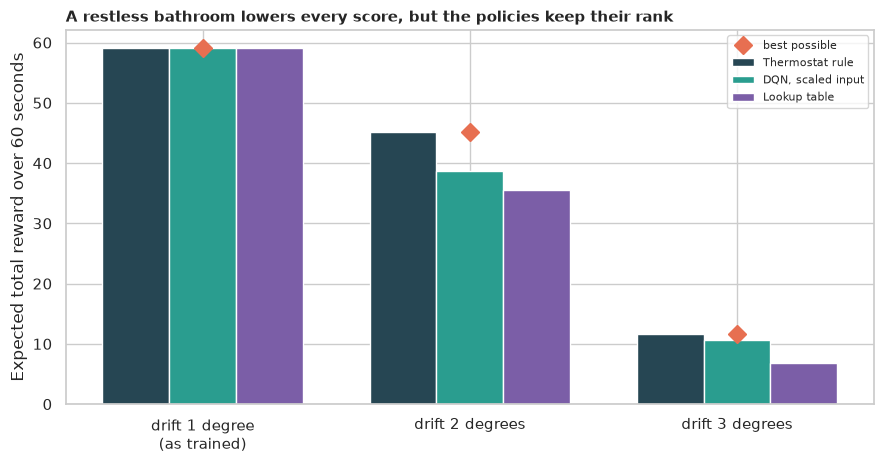

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.8))
width = 0.25
for i, (name, color) in enumerate(zip(policies_at_noise, [NAVY, TEAL, PURPLE], strict=True)):
    sub = noise_table.xs(name, level="policy")
    ax.bar(np.arange(3) + (i - 1) * width, sub["mean return"], width, color=color, label=name)
best_line = noise_table.xs("Thermostat rule", level="policy")["best possible"]
ax.plot(np.arange(3), best_line, color=ORANGE, marker="D", ls="", ms=9, label="best possible")
ax.set_xticks(np.arange(3), ["drift 1 degree\n(as trained)", "drift 2 degrees", "drift 3 degrees"])
ax.set_ylabel("Expected total reward over 60 seconds")
ax.set_title(
    "A restless bathroom lowers every score, but the policies keep their rank",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_noise.png", dpi=150)
plt.show()

**How to read this:**

- **At the drift they were trained on,** all three are optimal (**59.14**).
- **At drift 2** the best possible score is **45.19**. The thermostat rule still achieves it (regret 0.00). The rescaled DQN averages **38.62** (regret **6.56**, worst **13.11**) and the lookup table **35.48** (regret **9.71**, worst **18.24**).
- **At drift 3** the best possible score is **11.58**: the thermostat gets it, the DQN gets **10.61** (regret 0.96, worst 1.85) and the lookup table **6.90** (regret 4.68, worst 6.37).
- **The ranking never changes** (thermostat, then DQN, then table). Part of the agents' lost score is the same reason as in H3: a noisier shower pushes them into temperatures their training rarely visited. **We reject H₀:** regret rises above 0 as soon as the shower gets more restless than the one the agents practised in.
- So a learned policy is only as good as the situations it practised, while the one-line thermostat rule works for every level of drift.

## 10. 🎯 Takeaways

1. **Solve the problem exactly when you can.** A thermostat rule scores 59.14, exactly the best possible, while random twiddling scores -35.27 and never touching the knob -28.32. This is the benchmark every learner is judged against.
2. **Rescale the inputs.** With 10,000 steps the rescaled DQN is optimal in 8 of 8 seeds; the raw-input agent in 0 of 8, and at 50,000 steps only 2 of 8.
3. **A lookup table learned faster than the neural network** (regret 0.05 against 32.67 at 2,000 steps, p = 0.029) and both are perfect from 10,000 steps: choose the simplest learner that fits the problem.
4. **Learned rules do not travel.** Outside the 35 to 41 degrees they practised, the agents are near-optimal from only 21% (table) to 60% (rescaled DQN) of starting temperatures; the thermostat rule is optimal everywhere.
5. **Check robustness before trusting a policy:** in a more restless shower the learned agents lose 6.6 (DQN) and 9.7 (table) points of an optimum of 45.2, and the thermostat rule loses none.

## 11. ⚠️ Limitations

- **A tiny, fully known problem.** The point is to see the learners clearly; real control problems are larger, partly hidden and not exactly solvable, so these comparisons will not carry over directly.
- **One recipe for each agent.** We did not tune the DQN or the table (learning rate, exploration, network size); a tuned raw-input DQN might recover some of the gap in H1.
- **Few seeds** (8 per setting), so p-values sit at or near their minimum possible value, and the 37% to 100% spread in H3 shows how much luck there is.
- **Discounting.** The agents learn with a discount of 0.9, while we score them by the undiscounted 60-second return; for this problem the best rule is the same under both.
- **The agent sees only the temperature.** It does not see the time left, which does not matter here because the best action never depends on it.
- **The learning budgets stop at 50,000 steps,** so we cannot say whether the raw-input agent would eventually become reliable (the legacy notebook used 500,000).
- **A reduced, whole-degree shower.** Real water temperature is continuous, and real drift is not uniform.